# Regress a real target with quantum and classical features

Use a bounded subset of real diabetes measurements to learn preprocessing, regression metrics, and saved-model parity. This is a software benchmark, not a medical decision model.

## 1. Set up

Expected runtime is measured in the execution report, not guaranteed for every machine. The examples run locally on simulators; no QPU account is needed.

In [1]:
import importlib.util, os, subprocess, sys
# Locally: clone this repository, create a Python 3.12 environment, and install
# pip install -e ".[qiskit,learning,notebooks]"
# In Colab: set the public GitHub URL here once the repository is published.
REPO_URL = os.environ.get("QML_TRICKS_REPO_URL", "")
if importlib.util.find_spec("qml_tricks") is None:
    if not REPO_URL:
        raise RuntimeError("Set REPO_URL to the public GitHub repository, or install this checkout first.")
    subprocess.check_call([sys.executable, "-m", "pip", "install", f"qml-bag-of-tricks[qiskit,learning,notebooks] @ git+{REPO_URL}"])
FRAMEWORK = "qiskit"  # switch to pennylane or cirq after installing its extra
import json, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
from qml_tricks.learning.models import QMLModel
ARTIFACTS = Path("results/local/notebooks")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
print("Python:", sys.version.split()[0], "Framework:", FRAMEWORK)


Python: 3.12.3 Framework: qiskit


## 2. Split before preprocessing

The QML estimator scales targets internally using training statistics. The classical control also scales targets inside its fit. RMSE and MAE below are returned in the original target units.

In [2]:
from qml_tricks.learning.study import dataset
from sklearn.model_selection import train_test_split
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error
X, y, _, provenance = dataset("diabetes", 128)
train, test = train_test_split(np.arange(len(X)), test_size=.25, random_state=17)
assert not set(train) & set(test)
quantum = QMLModel("frozen_features", task="regression", framework=FRAMEWORK, seed=17)
classical = TransformedTargetRegressor(regressor=make_pipeline(StandardScaler(), Ridge(alpha=.1)), transformer=StandardScaler())
quantum.fit(X[train], y[train]); classical.fit(X[train], y[train])


,"regressor regressor: object, default=NoneRegressor object such as derived from:class:`~sklearn.base.RegressorMixin`. This regressor willautomatically be cloned each time prior to fitting. If `regressor isNone`, :class:`~sklearn.linear_model.LinearRegression` is created and used.",Pipeline(step...(alpha=0.1))])
,"transformer transformer: object, default=NoneEstimator object such as derived from:class:`~sklearn.base.TransformerMixin`. Cannot be set at the same timeas `func` and `inverse_func`. If `transformer is None` as well as`func` and `inverse_func`, the transformer will be an identitytransformer. Note that the transformer will be cloned during fitting.Also, the transformer is restricting `y` to be a numpy array.",StandardScaler()
,"func func: function, default=NoneFunction to apply to `y` before passing to :meth:`fit`. Cannot be setat the same time as `transformer`. If `func is None`, the function used will bethe identity function. If `func` is set, `inverse_func` also needs to beprovided. The function needs to return a 2-dimensional array.",None
,"inverse_func inverse_func: function, default=NoneFunction to apply to the prediction of the regressor. Cannot be set atthe same time as `transformer`. The inverse function is used to returnpredictions to the same space of the original training labels. If`inverse_func` is set, `func` also needs to be provided. The inversefunction needs to return a 2-dimensional array.",None
,"check_inverse check_inverse: bool, default=TrueWhether to check that `transform` followed by `inverse_transform`or `func` followed by `inverse_func` leads to the original targets.",True
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying regressor exposes such an attribute when fit... versionadded:: 0.24,int,10
regressor_ regressor_: objectFitted regressor.,Pipeline,Pipeline(step...(alpha=0.1))])
transformer_ transformer_: objectTransformer used in :meth:`fit` and :meth:`predict`.,StandardScaler,StandardScaler()
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None


## 3. Evaluate once on held-out rows

Lower error is better. Two qubits and PCA are a deliberate small representation: the stronger full-feature classical control is essential.

{
  "Quantum frozen features": {
    "rmse": 81.23719887945218,
    "mae": 73.24572300087165
  },
  "Classical ridge": {
    "rmse": 64.66206862573935,
    "mae": 52.92267317370353
  }
}


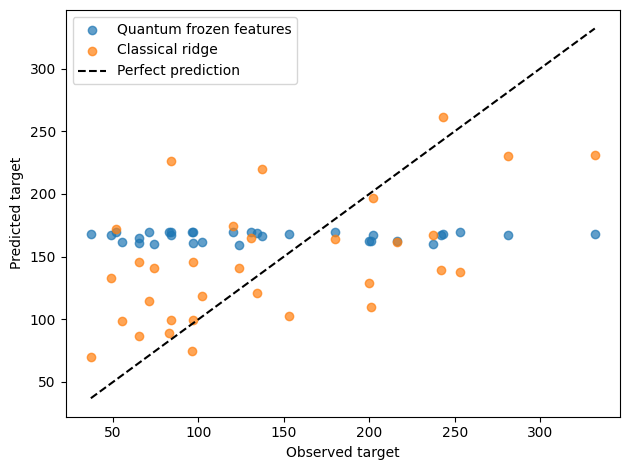

In [3]:
reports = {}; predictions = {}
for label, model in [("Quantum frozen features", quantum), ("Classical ridge", classical)]:
    pred = model.predict(X[test]); predictions[label] = pred
    reports[label] = {"rmse": float(np.sqrt(mean_squared_error(y[test], pred))), "mae": float(mean_absolute_error(y[test], pred))}
print(json.dumps(reports, indent=2))
for label, pred in predictions.items(): plt.scatter(y[test], pred, label=label, alpha=.7)
limits=[min(y[test]), max(y[test])]; plt.plot(limits, limits, "k--", label="Perfect prediction")
plt.xlabel("Observed target"); plt.ylabel("Predicted target"); plt.legend(); plt.tight_layout(); plt.show()


## 4. Save and reproduce

Avoid selecting settings from this test plot. Use the separate repeated-seed, validation-selected benchmark for comparative evidence.

In [4]:
assert np.allclose(quantum.scaler_.mean_, X[train].mean(axis=0))
path = ARTIFACTS / "diabetes_frozen_features.joblib"; quantum.save(path)
assert np.allclose(QMLModel.load(path).predict(X[test]), predictions["Quantum frozen features"])
(ARTIFACTS / "regression.json").write_text(json.dumps(reports, indent=2))
print(json.dumps(quantum.resources_, indent=2))


{
  "state_preparations": 128,
  "measurement_shots": 0,
  "kernel_pair_evaluations": 0,
  "warm_start_state_preparations": 0,
  "training_seconds": 0.6655101000069408,
  "statevector_bytes": 64,
  "state_preparations_meaning": "native simulator executions, not hardware state copies",
  "full_density_teacher": false,
  "density_embedding_bytes": 0,
  "simulator_only": true,
  "data_access": "classical feature vectors or known simulator preparation descriptions"
}
